# DATA-445: In-Class Assignment 18
---

## 1. Customer Segmentation

Consider the `customers.csv` datafile. This file contains information related to customers' activity on a company website. Below are the description of the variables.

- **ID:** customer ID
- **Visit_Time:** The number of visits to the company's website in a given month.
- **Average_Expense:** The average amount of money that the customer has spend.
- **Sex:** gender of the customer (0: female, 1: male).
- **Age:** age of the customer.

**In Python**, answer the following:

### (a) (3 points) 
Using the `pandas` library, read the csv file and create a data-frame called `customers`.

In [13]:
import pandas as pd

customers = pd.read_csv('customers.csv')
customers.head()

,ID,Visit_Time,Average_Expense,Sex,Age
0,1,3,5.7,0,10
1,2,5,14.5,0,27
2,3,16,33.5,0,32
3,4,5,15.9,0,30
4,5,16,24.9,0,23


### (b) (3 points) 
Using the appropriate Python commands, remove the `ID` variable.

In [14]:
customers = customers.drop(columns=['ID'], axis=1)
customers.head()

,Visit_Time,Average_Expense,Sex,Age
0,3,5.7,0,10
1,5,14.5,0,27
2,16,33.5,0,32
3,5,15.9,0,30
4,16,24.9,0,23


### (c) (8 points) 
Compute the principal component of the data and visualize the variance explained ratio. How many components would you consider for this dataset? Make sure the put the data on the same scale.

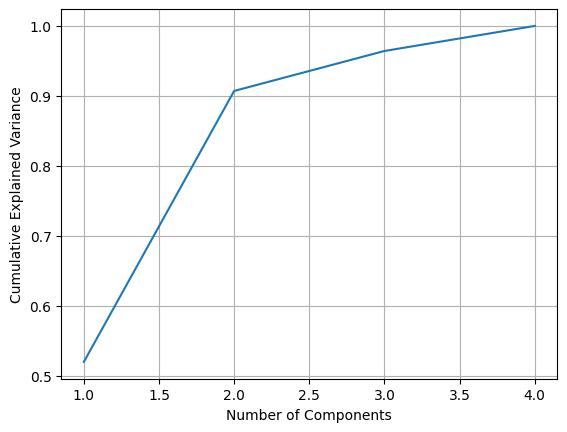

In [27]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA

scaler = MinMaxScaler()
customers_scaled = scaler.fit_transform(customers)

pca = PCA()

customers_pca = pca.fit_transform(customers_scaled)

pca.explained_variance_ratio_

import matplotlib.pyplot as plt
n_components = [i for i in range(1, customers.shape[1] + 1)]
plt.plot(n_components, pca.explained_variance_ratio_.cumsum())
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.grid(True)
plt.show()

Because the first three components explain more than 95% of the variability in the data, we select the first three components.

### (d) (8 points) 
Based on the answer from part (c), compute that number of component and visualize them to estimate the number of cluster in this dataset.

In [28]:
components = customers_pca[:, :3]

import plotly.express as px

components_df = pd.DataFrame(components, columns=['PC1', 'PC2', 'PC3'])

fig = px.scatter_3d(components_df, x='PC1', y='PC2', z='PC3')
fig.update_traces(marker=dict(size=4))
fig.update_layout(margin=dict(l=0, r=0, b=0, t=0))
fig.show()

It seems that there are four groups based on the first three components

### (e) (6 points) 
Based on the answer from part (d), cluster those components with $k$-means.

In [29]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
components_scaled = scaler.fit_transform(components)

kmeans = KMeans(n_clusters=4, n_init=20, random_state=42)
kmeans.fit(components_scaled)
labels = kmeans.labels_

c:\Users\15154\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning:

KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.



### (f) (4 points) 
Describe the clusters.

In [30]:
customers['Cluster'] = labels
customers.head()

,Visit_Time,Average_Expense,Sex,Age,Cluster
0,3,5.7,0,10,0
1,5,14.5,0,27,0
2,16,33.5,0,32,1
3,5,15.9,0,30,0
4,16,24.9,0,23,1


In [ ]:
customers.groupby('Cluster').mean()

In [32]:
customers.corr()

,Visit_Time,Average_Expense,Sex,Age,Cluster
Visit_Time,1.000000,0.776120,-0.075612,0.601689,-0.052139
Average_Expense,0.776120,1.000000,-0.087724,0.700697,0.000455
Sex,-0.075612,-0.087724,1.000000,0.028147,0.815793
Age,0.601689,0.700697,0.028147,1.000000,0.238151
Cluster,-0.052139,0.000455,0.815793,0.238151,1.000000
